# Proyecto Final - Data Science (Fundación YPF - Ingenias+)
## Análisis de Eficiencia Académica y Retención en las Universidades Públicas Argentinas
**Pre-entregas integradas:**
- **2ª Pre-entrega:** Análisis Exploratorio de Datos (AED), limpieza, imputación de faltantes, outliers y Feature Engineering.
- **3ª Pre-entrega:** Modelado supervisado de punta a punta (clasificación y regresión), validación cruzada y optimización de hiperparámetros evitando el sobreajuste (overfitting).

### 1. Conexión a Google Drive e Importación de Librerías

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Conectar con Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Estilos para los gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('viridis')
print("Entorno configurado correctamente.")

Mounted at /content/drive
Entorno configurado correctamente.


### 2. Carga y Consolidación de Datos (Pre-entrega 2)


In [12]:

# ==========================================
# 2. CARGA Y CURACIÓN DE DATOS (AED PARTE 1)
# ==========================================
ruta_indicadores = '/content/drive/MyDrive/DATA SCIENCE - PROYECTO FINAL/Z 1.2 Indicadores 24.xlsx'

# 1. Leer hoja de Estudiantes (Cuadro 1.2.1a) saltando los títulos decorativos
df_raw_est = pd.read_excel(ruta_indicadores, sheet_name='C 1.2.1a', skiprows=4)

df_est = pd.DataFrame({
    'institucion': df_raw_est.iloc[:, 1],
    'estudiantes_totales': df_raw_est.iloc[:, 2],
    'nuevos_inscriptos': df_raw_est.iloc[:, 4],
    'reinscriptos': df_raw_est.iloc[:, 6],
    'egresados': df_raw_est.iloc[:, 8],
    'pct_mujeres_estudiantes': df_raw_est.iloc[:, 10],
    'pct_ri_materias_aprobadas': df_raw_est.iloc[:, 16],
    'pct_ingresantes': df_raw_est.iloc[:, 17]
}).dropna(subset=['institucion'])

# Filtramos filas de totales generales
df_est = df_est[~df_est['institucion'].astype(str).str.startswith('Total')].copy()

# 2. Leer hoja de Recursos Humanos / Docentes (Cuadro 1.2.2)
df_raw_rh = pd.read_excel(ruta_indicadores, sheet_name='C 1.2.2', skiprows=6)

df_rh = pd.DataFrame({
    'institucion': df_raw_rh.iloc[:, 0],
    'docentes_univ': df_raw_rh.iloc[:, 3],
    'pct_dedicacion_exclusiva': df_raw_rh.iloc[:, 30]
}).dropna(subset=['institucion'])

df_rh = df_rh[~df_rh['institucion'].astype(str).str.startswith('Total')].copy()

# 3. Unir ambos DataFrames por Institución
df = pd.merge(df_est, df_rh, on='institucion', how='inner')

# Casteo y limpieza de valores numéricos
cols_num = [
    'estudiantes_totales', 'nuevos_inscriptos', 'reinscriptos', 'egresados',
    'pct_mujeres_estudiantes', 'pct_ri_materias_aprobadas', 'pct_ingresantes',
    'docentes_univ', 'pct_dedicacion_exclusiva'
]

for c in cols_num:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.').replace('-', np.nan), errors='coerce')

print(f"✓ Dataset unificado con éxito: {df.shape[0]} universidades y {df.shape[1]} columnas.")
df.head()

✓ Dataset unificado con éxito: 57 universidades y 10 columnas.


,institucion,estudiantes_totales,nuevos_inscriptos,reinscriptos,egresados,pct_mujeres_estudiantes,pct_ri_materias_aprobadas,pct_ingresantes,docentes_univ,pct_dedicacion_exclusiva
0,Alto Uruguay,1349.0,358.0,991.0,21.0,72.4,50.2,27.0,98.0,0.014925
1,Artes,22932.0,7956.0,14976.0,82.0,71.3,59.5,34.7,2178.0,0.007274
2,Arturo Jauretche,35231.0,12910.0,22321.0,1049.0,69.2,46.9,36.6,1623.0,0.079590
3,Avellaneda,19766.0,6893.0,12873.0,634.0,59.9,49.3,34.9,1133.0,0.031230
4,Buenos Aires,304567.0,63913.0,240654.0,22440.0,64.8,58.1,21.0,24136.0,0.057937


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 3. Feature Engineering, Faltantes y Outliers

In [19]:
from sklearn.impute import SimpleImputer

# 1. Creación de Variables Derivadas
df['ratio_estudiante_docente'] = df['estudiantes_totales'] / (df['docentes_univ'] + 1)
df['tasa_egreso'] = (df['egresados'] / (df['estudiantes_totales'] + 1)) * 100

# 2. Imputación de Faltantes con Mediana (robusta frente a asimetría)
imputer = SimpleImputer(strategy='median')
df[cols_num] = imputer.fit_transform(df[cols_num])
df['ratio_estudiante_docente'] = df['ratio_estudiante_docente'].fillna(df['ratio_estudiante_docente'].median())
df['tasa_egreso'] = df['tasa_egreso'].fillna(df['tasa_egreso'].median())

# 3. Detección de Outliers (Rango Intercuartílico - IQR)
q1 = df['estudiantes_totales'].quantile(0.25)
q3 = df['estudiantes_totales'].quantile(0.75)
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
outliers = df[df['estudiantes_totales'] > lim_sup]
print(f"Universidades de gran escala identificadas como outliers: {outliers['institucion'].tolist()}")

# 4. Definición de Target para Clasificación (1 = Alta regularidad, 0 = Regularidad moderada/baja)
umbral = df['pct_ri_materias_aprobadas'].median()
df['target_alto_rendimiento'] = (df['pct_ri_materias_aprobadas'] >= umbral).astype(int)
print("Distribución del target:")
print(df['target_alto_rendimiento'].value_counts())

Universidades de gran escala identificadas como outliers: ['Buenos Aires', 'Córdoba', 'La Plata', 'Rosario', 'Tucumán']
Distribución del target:
target_alto_rendimiento
1    30
0    27
Name: count, dtype: int64


### 4. Visualización y Análisis Exploratorio (Storytelling)

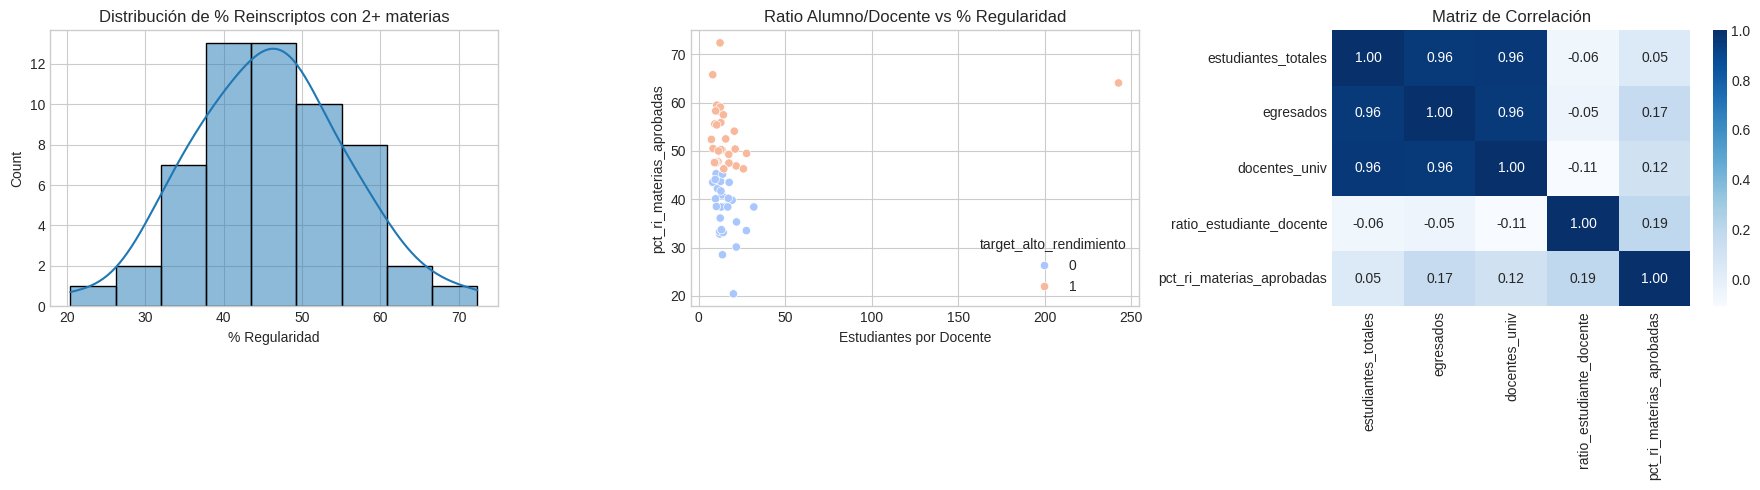

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Histograma y KDE de regularidad académica
sns.histplot(df['pct_ri_materias_aprobadas'], kde=True, ax=axes[0], color='#1f77b4')
axes[0].set_title('Distribución de % Reinscriptos con 2+ materias')
axes[0].set_xlabel('% Regularidad')

# Gráfico 2: Dispersión Ratio Alumno/Docente vs Regularidad
sns.scatterplot(data=df, x='ratio_estudiante_docente', y='pct_ri_materias_aprobadas',
                hue='target_alto_rendimiento', palette='coolwarm', ax=axes[1])
axes[1].set_title('Ratio Alumno/Docente vs % Regularidad')
axes[1].set_xlabel('Estudiantes por Docente')

# Gráfico 3: Matriz de Correlación de variables estructurales
cols_corr = ['estudiantes_totales', 'egresados', 'docentes_univ', 'ratio_estudiante_docente', 'pct_ri_materias_aprobadas']
sns.heatmap(df[cols_corr].corr(), annot=True, cmap='Blues', fmt='.2f', ax=axes[2])
axes[2].set_title('Matriz de Correlación')

plt.tight_layout()
plt.show()

### 5. Modelado Supervisado y Optimización de Hiperparámetros (Pre-entrega 3)
- Partición `train_test_split` estratificada.
- `Pipeline` con escalado (`StandardScaler`) y modelo para prevenir fuga de datos (*data leakage*).
- `StratifiedKFold` (5 pliegues) y `GridSearchCV` para regularización y ajuste.

Mejores parámetros: {'clf__max_depth': 2, 'clf__min_samples_leaf': 4, 'clf__n_estimators': 200}
ROC-AUC en Validación Cruzada: 0.700

--- Reporte de Clasificación en Test ---
              precision    recall  f1-score   support

           0       0.57      0.67      0.62         6
           1       0.60      0.50      0.55         6

    accuracy                           0.58        12
   macro avg       0.59      0.58      0.58        12
weighted avg       0.59      0.58      0.58        12

ROC-AUC en Test: 0.778


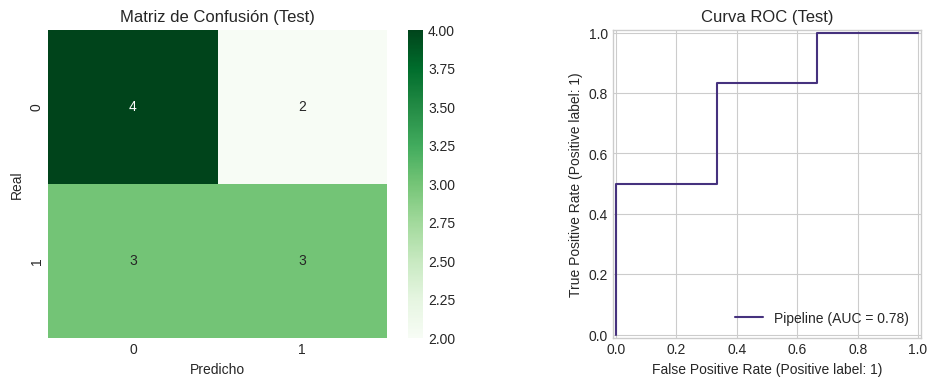

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

# Variables predictoras (X) y objetivo (y)
features = [
    'estudiantes_totales', 'nuevos_inscriptos', 'reinscriptos',
    'pct_mujeres_estudiantes', 'pct_ingresantes', 'docentes_univ',
    'pct_dedicacion_exclusiva', 'ratio_estudiante_docente', 'tasa_egreso'
]

X = df[features]
y = df['target_alto_rendimiento']

# Separación Train/Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Pipeline
pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=42))
])

# Grilla de hiperparámetros para controlar overfitting
param_grid = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [2, 3, 5, None],
    'clf__min_samples_leaf': [1, 2, 4]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipe_rf, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print(f"Mejores parámetros: {grid.best_params_}")
print(f"ROC-AUC en Validación Cruzada: {grid.best_score_:.3f}")

# Evaluación final en el conjunto de test
best_clf = grid.best_estimator_
y_pred = best_clf.predict(X_test)
y_prob = best_clf.predict_proba(X_test)[:, 1]

print("\n--- Reporte de Clasificación en Test ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC en Test: {roc_auc_score(y_test, y_prob):.3f}")

# Visualización de Matriz de Confusión y Curva ROC
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens', ax=ax1)
ax1.set_title('Matriz de Confusión (Test)')
ax1.set_xlabel('Predicho')
ax1.set_ylabel('Real')

RocCurveDisplay.from_estimator(best_clf, X_test, y_test, ax=ax2)
ax2.set_title('Curva ROC (Test)')
plt.show()